# PanEcho – EchoNet-Dynamic Evaluation

This notebook evaluates the best fine-tuned PanEcho checkpoint on the **official test split**. It saves predictions, metrics and plots. Do not use the test results to repeatedly tune training settings.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Open this notebook from inside your ml-service project.")
    PROJECT_ROOT = PROJECT_ROOT.parent

import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.datasets.panecho_echonet_dataset import PanEchoEchoNetDataset, load_echonet_records
from src.models.echo.panecho import load_panecho
from src.evaluation.evaluate_echo_panecho import predict_loader, summarize

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [2]:
# File locations and evaluation settings
MANIFEST_PATH = PROJECT_ROOT / "data" / "processed" / "echo" / "echonet" / "echonet_panecho_manifest.csv"
PRETRAINED_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho.pt"
FINE_TUNED_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho" / "panecho_echonet_finetuned.pt"
RESULTS_DIR = PROJECT_ROOT / "artifacts" / "metrics" / "echo" / "panecho"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

NUM_CLIPS = 8
BATCH_SIZE = 1
NUM_WORKERS = 2

for path in [MANIFEST_PATH, FINE_TUNED_CHECKPOINT]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

print("Manifest:", MANIFEST_PATH)
print("Checkpoint:", FINE_TUNED_CHECKPOINT)

Manifest: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\processed\echo\echonet\echonet_panecho_manifest.csv
Checkpoint: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho\panecho_echonet_finetuned.pt


In [3]:
# Load only the official test split
records = load_echonet_records(
    manifest=MANIFEST_PATH,
    project_root=PROJECT_ROOT,
)

test_dataset = PanEchoEchoNetDataset(
    records,
    split="test",
    num_clips=NUM_CLIPS,
    augment=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print("Test videos:", len(test_dataset))
print("Clips per video:", NUM_CLIPS)

Test videos: 182
Clips per video: 8


In [4]:
# Load the fine-tuned model and make predictions
model = load_panecho(
    FINE_TUNED_CHECKPOINT,
    tasks="auto",
    device=DEVICE,
)

predictions = predict_loader(model, test_loader, DEVICE)
print("Predictions:", predictions.shape)
display(predictions.head())

Predictions: (182, 7)


,video_path,EF_pred,EF_true,LVEDV_pred,LVEDV_true,LVESV_pred,LVESV_true
0,D:\Programming\VS Code\Projects\CardioFusion-X...,57.585938,55.951790,91.867188,107.731575,39.070312,47.453831
1,D:\Programming\VS Code\Projects\CardioFusion-X...,38.726562,41.014423,157.390625,121.011154,93.328125,71.379128
2,D:\Programming\VS Code\Projects\CardioFusion-X...,56.957031,50.794720,69.152344,68.990913,29.392578,33.947174
3,D:\Programming\VS Code\Projects\CardioFusion-X...,45.449219,50.634983,103.375000,68.233627,57.957031,33.683544
4,D:\Programming\VS Code\Projects\CardioFusion-X...,60.699219,63.098087,114.156250,128.385712,45.734375,47.376785


In [5]:
# Calculate regression and EF classification metrics
metrics = summarize(predictions)

absolute_error = (predictions["EF_true"] - predictions["EF_pred"]).abs()
metrics["EF_within_5_points_percent"] = float((absolute_error <= 5).mean() * 100)
metrics["EF_within_10_points_percent"] = float((absolute_error <= 10).mean() * 100)

output_dir = RESULTS_DIR / "finetuned_full_data"
output_dir.mkdir(parents=True, exist_ok=True)
predictions.to_csv(output_dir / "predictions.csv", index=False)
(output_dir / "metrics.json").write_text(
    json.dumps({
        "checkpoint": str(FINE_TUNED_CHECKPOINT),
        "split": "test",
        "num_clips": NUM_CLIPS,
        **metrics,
    }, indent=2),
    encoding="utf-8",
)

print(json.dumps(metrics, indent=2))
print("Saved results to:", output_dir)

{
  "n_videos": 182,
  "EF_MAE": 4.9195829433399245,
  "EF_RMSE": 7.043514699563174,
  "EF_R2": 0.6561439280925774,
  "LVEDV_MAE": 18.49285913823725,
  "LVEDV_RMSE": 24.99610526575298,
  "LVEDV_R2": 0.6807618175927549,
  "LVESV_MAE": 10.151926279067993,
  "LVESV_RMSE": 15.864613352687284,
  "LVESV_R2": 0.7870261005665631,
  "EF_<50_Accuracy": 0.9065934065934066,
  "EF_<40_Accuracy": 0.945054945054945,
  "EF_<50_auroc": 0.9392708333333333,
  "EF_<50_auprc": 0.8172909780418954,
  "EF_<50_f1": 0.7213114754098361,
  "EF_<50_precision": 0.7586206896551724,
  "EF_<50_recall": 0.6875,
  "EF_<40_auroc": 0.9688346883468835,
  "EF_<40_auprc": 0.8217520411379088,
  "EF_<40_f1": 0.6875,
  "EF_<40_precision": 0.7857142857142857,
  "EF_<40_recall": 0.6111111111111112,
  "EF_within_5_points_percent": 62.08791208791209,
  "EF_within_10_points_percent": 89.01098901098901
}
Saved results to: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\artifacts\metrics\echo\panecho\finetuned_full_data


In [6]:
# Show the main EF results
for name in ["EF_MAE", "EF_RMSE", "EF_R2", "EF_within_5_points_percent", "EF_<50_auroc", "EF_<50_recall", "EF_<40_auroc", "EF_<40_recall"]:
    if name in metrics:
        print(f"{name}: {metrics[name]:.4f}")

EF_MAE: 4.9196
EF_RMSE: 7.0435
EF_R2: 0.6561
EF_within_5_points_percent: 62.0879
EF_<50_auroc: 0.9393
EF_<50_recall: 0.6875
EF_<40_auroc: 0.9688
EF_<40_recall: 0.6111


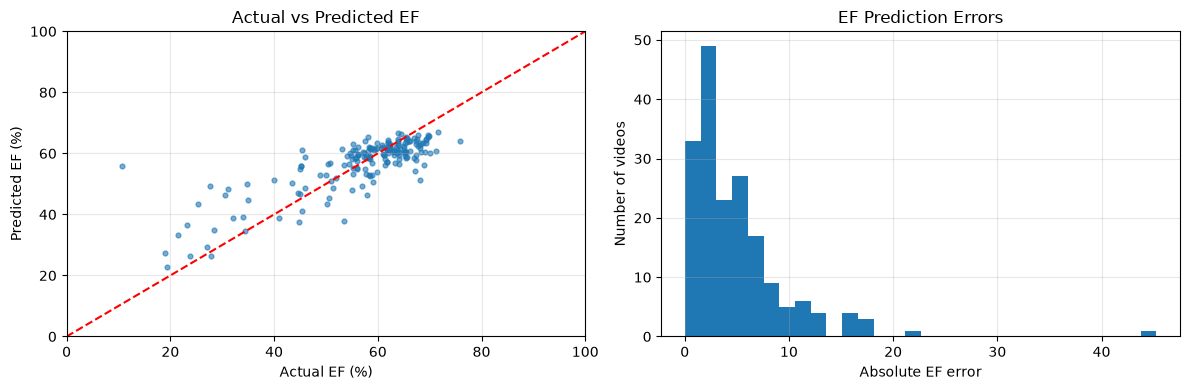

In [7]:
# Compare true EF with predicted EF
comparison = predictions.copy()
comparison["absolute_error"] = (comparison["EF_true"] - comparison["EF_pred"]).abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(comparison["EF_true"], comparison["EF_pred"], s=12, alpha=0.6)
axes[0].plot([0, 100], [0, 100], "r--")
axes[0].set_xlabel("Actual EF (%)")
axes[0].set_ylabel("Predicted EF (%)")
axes[0].set_title("Actual vs Predicted EF")
axes[0].set_xlim(0, 100)
axes[0].set_ylim(0, 100)
axes[0].grid(alpha=0.3)

axes[1].hist(comparison["absolute_error"], bins=30)
axes[1].set_xlabel("Absolute EF error")
axes[1].set_ylabel("Number of videos")
axes[1].set_title("EF Prediction Errors")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()